In [44]:
from langchain_text_splitters import RecursiveCharacterTextSplitter, MarkdownHeaderTextSplitter
from pathlib import Path
import re
from glob import glob

CHUNK_SIZE: int = 700
CHUNK_OVERLAP: int = 100

docs = glob("../docs/**/*.md", recursive=True)

loaded_docs = []
for doc in docs:
    content = Path(doc).read_text(encoding="utf-8")
    print(f"Processing {doc} with {len(content)} characters")
    doc_contents = {}
    doc_contents["filename"] = Path(doc).name
    doc_contents["path"] = doc
    doc_contents["content"] = content
    loaded_docs.append(doc_contents)

Processing ../docs/claims_guide.md with 9337 characters
Processing ../docs/policy_wording/HOME-STD.md with 8325 characters
Processing ../docs/policy_wording/HOME-PLUS.md with 8788 characters
Processing ../docs/policy_wording/HOME-BASIC.md with 7071 characters


In [45]:
def front_matter(text: str) -> tuple[dict[str, str], str]:
    match = re.match(r"^---\n(.*?)\n---\n", text, flags=re.DOTALL)
    metadata = dict(
        (key.strip(), value.strip().strip('"'))
        for key, value in (line.split(":", 1) for line in match.group(1).splitlines())
    )
    body = text[match.end():]
    return metadata, body

header_to_split_on = [
    ("#", "Header 1"),
    ("##", "Header 2"),
    ("###", "Header 3"),
]

markdown_splitter = MarkdownHeaderTextSplitter(
    headers_to_split_on=header_to_split_on,
)

text_splitter = RecursiveCharacterTextSplitter(chunk_size=CHUNK_SIZE, chunk_overlap=CHUNK_OVERLAP)

chunk_list = []
for doc in loaded_docs:
    yaml_metadata, body = front_matter(doc["content"])
    yaml_metadata["source"] = doc["path"]

    chunks = markdown_splitter.split_text(body)

    for c in chunks:
        chunk_list.append({
            **yaml_metadata,
            "chunk": c.metadata,
            "chunk_size": len(c.page_content),
            "chunk_splitter": "MarkdownHeaderTextSplitter",
            "content": c.page_content,
            "chunked_content": text_splitter.split_text(c.page_content),
        })

In [46]:
flat_chunks = []
for chunk in chunk_list:
    base = {k: v for k, v in chunk.items() if k not in ["chunked_content"]}
    for i, piece in enumerate(chunk["chunked_content"]):
        flat_chunks.append({
            **base,
            "chunk_index": i,
            "content": piece,
            "chunk_size": len(piece),
            "chunk_splitter": "RecursiveCharacterTextSplitter",
            "chunk_overlap": CHUNK_OVERLAP,
        })

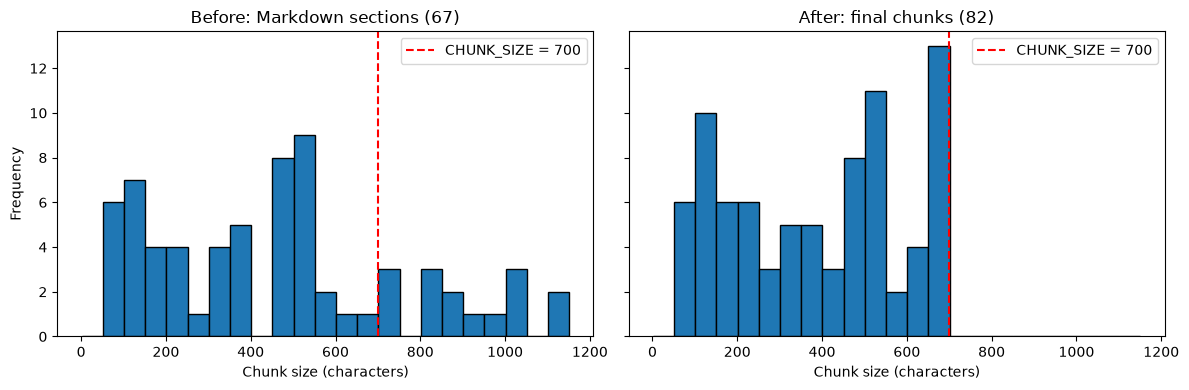

In [47]:
import matplotlib.pyplot as plt

section_sizes = [chunk["chunk_size"] for chunk in chunk_list]
final_sizes = [chunk["chunk_size"] for chunk in flat_chunks]
# Same 50-char bins in both plots. Edges start at 1 so a 700-char chunk lands in the 651-700 bin.
bins = range(1, max(section_sizes) + 51, 50)

fig, (ax_before, ax_after) = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)

ax_before.hist(section_sizes, bins=bins, edgecolor="black")
ax_before.set_title(f"Before: Markdown sections ({len(section_sizes)})")

ax_after.hist(final_sizes, bins=bins, edgecolor="black")
ax_after.set_title(f"After: final chunks ({len(final_sizes)})")

for ax in (ax_before, ax_after):
    ax.axvline(CHUNK_SIZE, color="red", linestyle="--", label=f"CHUNK_SIZE = {CHUNK_SIZE}")
    ax.set_xlabel("Chunk size (characters)")
    ax.legend()
ax_before.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [48]:
from sentence_transformers import SentenceTransformer

MODEL_NAME: str = "all-MiniLM-L6-v2"
model: SentenceTransformer = SentenceTransformer(MODEL_NAME)

def embed_chunks(chunks: list[dict]) -> list[dict]:
    texts: list[str] = [chunk["content"] for chunk in chunks]
    vectors = model.encode(texts, show_progress_bar=True)

    return [
        {**chunk, "vector": vector.tolist()}
        for chunk, vector in zip(chunks, vectors)
    ]


embedded_chunks = embed_chunks(flat_chunks)


Batches: 100%|██████████| 3/3 [00:00<00:00, 20.48it/s]


In [49]:
chunk_list[0]["chunk_size"]

473

In [50]:
# tokenizer gives me a list of input_ids, which the length of is the number of tokens in the chunk.
token_counts = []
for chunk in embedded_chunks:
    tokenized = model.tokenizer(chunk["content"])
    if len(tokenized["input_ids"]) > 256:
        print(f"Chunk index {chunk['chunk_index']} in file {chunk['source']} exceeds 256 tokens with {len(tokenized['input_ids'])} tokens.")
    token_counts.append(len(tokenized["input_ids"]))

import numpy as np

max_tokens = max(token_counts)
min_tokens = min(token_counts)
avg_tokens = round(np.average(token_counts), 0)

print(f"max tokens: {max_tokens} - limit use: {round((max_tokens / 256) * 100, 0)}%")
print(f"avg tokens: {avg_tokens} - limit use: {round((avg_tokens / 256) * 100, 0)}%")
print(f"min tokens: {min_tokens} - limit use: {round((min_tokens / 256) * 100, 0)}%")

max tokens: 215 - limit use: 84.0%
avg tokens: 101.0 - limit use: 39.0%
min tokens: 22 - limit use: 9.0%
